# 06 · Experiments summary

The released model is the result of two phases. In Phase 1 we built it through single-factor experiments and averaged
three seeds of the best recipe. In Phase 2 we looked for what still limits it, then ran one controlled experiment,
which came out negative. Every score below is recomputed from the run's own out-of-fold predictions. The reasoning
behind each decision is in `docs/experiment_log.md`.

_This model was developed for a research competition and is not a medical device._

In [1]:
# Setup: every path comes from configs/final.yaml (milk10k.config); nothing here downloads data.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RELEASE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(RELEASE / "src") not in sys.path:
    sys.path.insert(0, str(RELEASE / "src"))  # works without `pip install -e .`
from milk10k.config import load_config
from milk10k.evaluation import (CODE_GROUPS, COMPONENTS, bootstrap_mean_difference, ci95, evaluate, load_oof,
                                load_solution, truth_arrays)

cfg = load_config()
DATA = cfg["paths"]["data_dir"]  # prepared MILK10k (data/README.md); override with MILK10K_DATA_DIR

# "data:<file>" = under DATA; anything else is relative to the release root.
INPUTS = {
    "train_meta": "data:train_metadata.csv",
    "folds": "data/folds.csv",
    "experiments": "results/experiments_scores.csv",
    "oof_s42": "results/oof/P1a-kg-s42_oof.csv",
    "oof_s43": "results/oof/P1a-kg-s43_oof.csv",
    "oof_s44": "results/oof/P1a-kg-s44_oof.csv",
    "oof_noiseoff_s42": "results/oof/P1a-kg-noiseoff-s42_oof.csv",
    "oof_noiseoff_s43": "results/oof/P1a-kg-noiseoff-s43_oof.csv"
}
OUTPUTS = {
    "fig_experiments": "results/figures/06_experiment_scores.png",
    "table_families": "results/tables/06_seed_mean_families.csv",
    "table_phase2": "results/tables/06_phase2_noiseoff.csv",
    "fig_phase2": "results/figures/06_phase2_groups.png"
}


def inp(key):
    v = INPUTS[key]
    return DATA / v[5:] if v.startswith("data:") else RELEASE / v


def out(key):
    p = RELEASE / OUTPUTS[key]
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def savefig(key):
    plt.tight_layout()
    plt.savefig(out(key), dpi=120)
    plt.show()


missing = [k for k in INPUTS if not inp(k).exists()]
import os  # noqa: E402
print("data dir from:", "MILK10K_DATA_DIR" if os.environ.get("MILK10K_DATA_DIR") else "configs/final.yaml")
print("checkpoints from:", "MILK10K_CHECKPOINT_DIR" if os.environ.get("MILK10K_CHECKPOINT_DIR") else "configs/final.yaml")
print("missing inputs:", missing or "none")

data dir from: MILK10K_DATA_DIR
checkpoints from: configs/final.yaml
missing inputs: none


## 1. Every run, rescored
`results/experiments_scores.csv` holds one row per run, scored from that run's pooled OOF file. The sha256 of each file
is recorded next to its score.

In [2]:
exp = pd.read_csv(inp("experiments"))
exp[["run", "phase", "environment", "kind", "change", "recorded_decision", "score", "pauc80_norm", "macro_auc_11",
     "fair_gap"]].round(4)

,run,phase,environment,kind,change,recorded_decision,score,pauc80_norm,macro_auc_11,fair_gap
0,baseline,1,local RTX 3050 bf16,train,"ResNet18 x2, 224 px (before deterministic seed...",reference only,0.6141,0.5126,0.8698,0.0566
1,baseline-s42,1,local RTX 3050 bf16,train,"deterministic seeding, seed 42",local parent,0.6309,0.5332,0.8697,0.0320
2,baseline-s43,1,local RTX 3050 bf16,train,seed 43,noise floor,0.6154,0.5175,0.8695,0.0770
3,P1a-s42,1,local RTX 3050 bf16,train,"288 px, seed 42","promising, not confirmed",0.6393,0.5444,0.8705,0.0288
4,P1a-s43,1,local RTX 3050 bf16,train,"288 px, seed 43","promising, not confirmed",0.6406,0.5440,0.8757,0.0293
5,P1a-s42-evalfix,1,local RTX 3050 bf16,eval,clinical crop-to-fill eval,not adopted,0.6414,0.5465,0.8736,0.0327
6,P1a-s43-evalfix,1,local RTX 3050 bf16,eval,clinical crop-to-fill eval,not adopted,0.6403,0.5445,0.8753,0.0352
7,P1a-s42-noclin,1,local RTX 3050 bf16,eval,P4b: clinical image removed,ablation,0.6093,0.5187,0.8598,0.1169
8,P1a-s43-noclin,1,local RTX 3050 bf16,eval,P4b: clinical image removed,ablation,0.6258,0.5322,0.8656,0.0642
9,P1a-s42-tta,1,local RTX 3050 bf16,eval,P5a: 4-view flip TTA,unconfirmed,0.6467,0.5555,0.8768,0.0517


37 runs: 35 from Phase 1, including evaluation-only variants and the two final ensembles, and 2 from Phase 2.
Local runs (RTX 3050, bf16) and Kaggle runs (T4, fp16) are labelled because their scores are not directly comparable.

## 2. When is a change real?
Three seeds of the same recipe scored 0.6446, 0.6204 and 0.6237, so one run can swing by 0.02 without any real change.
Before running candidates on Kaggle we therefore fixed a rule. σ is the standard deviation of the three reference scores.
A candidate with n seeds is kept only if its mean beats the reference mean by
`T(n) = max(0.01, 2σ√(1/n + 1/3))`. It is dropped if it does not beat the reference at all; anything in between needs
another seed.

In [3]:
score = exp.set_index("run").score
ref = score[[f"P1a-kg-s{s}" for s in (42, 43, 44)]]
REF_MEAN, SIGMA = float(ref.mean()), float(ref.std(ddof=1))


def T(n):
    return max(0.01, 2 * SIGMA * np.sqrt(1 / n + 1 / 3))


print(f"reference mean {REF_MEAN:.4f} | sigma {SIGMA:.6f} | T(2) {T(2):.4f} | T(3) {T(3):.4f}")
families = {"P1a-kg reference (Kaggle)": ["P1a-kg-s42", "P1a-kg-s43", "P1a-kg-s44"],
            "P2a ConvNeXt-T (Kaggle)": ["P2a-s42", "P2a-s43"],
            "P4a cross-attention (Kaggle)": ["P4a-s42", "P4a-s43"],
            "Phase 2: GaussNoise off (Kaggle)": ["P1a-kg-noiseoff-s42", "P1a-kg-noiseoff-s43"],
            "baseline seeded 224 px (local)": ["baseline-s42", "baseline-s43"],
            "P1a 288 px (local)": ["P1a-s42", "P1a-s43"],
            "P1b 384 px (local)": ["P1b-s42", "P1b-s43"],
            "P3b-mel MEL weight 3 (local)": ["P3b-mel-s42", "P3b-mel-s43"]}
fam = pd.DataFrame([{"family": f, "n_seeds": len(rs), "mean_score": float(score[rs].mean()),
                     "kaggle_gate_delta": float(score[rs].mean() - REF_MEAN) if "(Kaggle)" in f else np.nan}
                    for f, rs in families.items()]).set_index("family")
fam["T_n"] = [T(n) if "(Kaggle)" in f else np.nan for f, n in zip(fam.index, fam.n_seeds)]
fam.to_csv(out("table_families"))
fam.round(4)  # local runs used their own rule: beat the parent by 2 x seed spread (0.031)

reference mean 0.6295 | sigma 0.013136 | T(2) 0.0240 | T(3) 0.0215


,n_seeds,mean_score,kaggle_gate_delta,T_n
family,,,,
P1a-kg reference (Kaggle),3,0.6295,0.0000,0.0215
P2a ConvNeXt-T (Kaggle),2,0.5928,-0.0368,0.0240
P4a cross-attention (Kaggle),2,0.5341,-0.0955,0.0240
Phase 2: GaussNoise off (Kaggle),2,0.6301,0.0005,0.0240
baseline seeded 224 px (local),2,0.6232,NaN,NaN
P1a 288 px (local),2,0.6400,NaN,NaN
P1b 384 px (local),2,0.6344,NaN,NaN
P3b-mel MEL weight 3 (local),2,0.6118,NaN,NaN


σ = 0.013136, so a two-seed candidate needs +0.0240 and a three-seed one +0.0215. On Kaggle, ConvNeXt-T and the
cross-attention fusion fall well below the reference; the Phase 2 candidate is level with it (+0.0005).

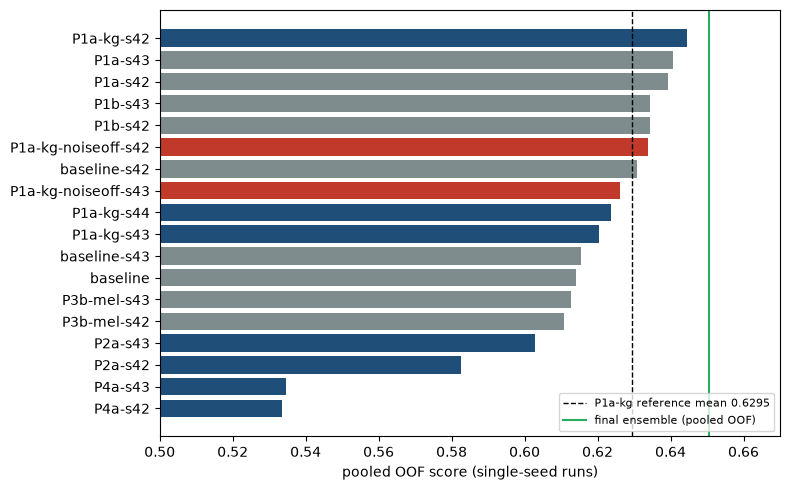

In [4]:
train_runs = exp[exp.kind == "train"].sort_values("score")
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#c0392b" if ph == 2 else ("#1f4e79" if "Kaggle" in env else "#7f8c8d")
          for ph, env in zip(train_runs.phase, train_runs.environment)]
ax.barh(train_runs.run, train_runs.score, color=colors)
ax.axvline(REF_MEAN, color="black", ls="--", lw=1, label=f"P1a-kg reference mean {REF_MEAN:.4f}")
ax.axvline(exp.set_index("run").score["final-P1a-kg"], color="#27ae60", lw=1.5, label="final ensemble (pooled OOF)")
ax.set_xlim(0.5, 0.67)
ax.set_xlabel("pooled OOF score (single-seed runs)")
ax.legend(loc="lower right", fontsize=8)
savefig("fig_experiments")

## 3. Phase 1 in short
- **288 px** beat 224 px locally (+0.0168) and became the recipe that the Kaggle reference repeats with three seeds.
- **384 px**, **weighting melanoma ×3 in the binary loss** and **blending the two heads** all lost and were dropped.
- **ConvNeXt-T** lost under our 10-epoch recipe while its loss was still falling. That rules out this recipe, not the backbone.
- **Spatial cross-attention** between the streams lost badly and also coped worse without the clinical image.
- **Removing the clinical image** at evaluation cost about 0.011, so the clinical view matters (notebook 05).
- **TTA** added about +0.005, which is not distinguishable from noise; it stays optional.
- The released model averages the three reference seeds (0.6505).

## 4. Phase 2: what limits the model, and one controlled test
Before trying anything new we diagnosed the remaining error (notebooks 02–04, `docs/experiment_log.md`):
- the training curves plateau late rather than showing undertraining;
- 427 of the 690 malignant lesions below the 80%-sensitivity cut are missed by all three seeds, mostly melanomas ranked below BKL, NV and AKIEC;
- preprocessing did not explain the hard cases, but `GaussNoise` visibly corrupts training images.

The noise was the one concrete defect, so we tested exactly that. `GaussNoise` was replaced by a no-op in its
`OneOf` slot, with everything else identical, including the software environment. We trained seeds 42 and 43 and
compared them with the three reference seeds.

In [5]:
sol = load_solution(DATA, inp("folds"))
t = truth_arrays(sol)
ev = {r: evaluate(t, sol, load_oof(inp(k), sol)) for r, k in
      {**{f"noiseoff-s{s}": f"oof_noiseoff_s{s}" for s in (42, 43)}, **{f"P1a-kg-s{s}": f"oof_s{s}" for s in (42, 43, 44)}}.items()}


def comp_row(name, runs):
    rows = [ev[r] for r in runs]
    out_ = {"runs": name, **{k: float(np.mean([x[k] for x in rows])) for k in COMPONENTS}}
    for g, label in CODE_GROUPS.items():
        out_[f"pauc80 {label}"] = float(np.mean([x["pauc80_by_group"].get(g, np.nan) for x in rows]))
    return out_


cand_runs, ref_runs = ["noiseoff-s42", "noiseoff-s43"], ["P1a-kg-s42", "P1a-kg-s43", "P1a-kg-s44"]
p2 = pd.DataFrame([comp_row(r, [r]) for r in cand_runs]
                  + [comp_row("candidate mean (n=2)", cand_runs), comp_row("reference mean (n=3)", ref_runs)]).set_index("runs")
delta = p2.loc["candidate mean (n=2)", COMPONENTS] - p2.loc["reference mean (n=3)", COMPONENTS]
decomposition = {"delta_score": delta["score"], "from_pauc80 (0.7x)": 0.7 * delta["pauc80_norm"],
                 "from_macro_auc (0.3x)": 0.3 * delta["macro_auc_11"], "from_fairgap (-0.1x)": -0.1 * delta["fair_gap"]}
p2.to_csv(out("table_phase2"))
display(p2.round(4))
{k: round(v, 5) for k, v in decomposition.items()}

,score,pauc80_norm,macro_auc_11,fair_gap,pauc80 codes 1-2,pauc80 codes 3-4,pauc80 codes 5-6
runs,,,,,,,
noiseoff-s42,0.6339,0.5417,0.8717,0.0678,0.5016,0.5267,0.5694
noiseoff-s43,0.6262,0.5314,0.8687,0.0633,0.4917,0.5168,0.5550
candidate mean (n=2),0.6301,0.5365,0.8702,0.0655,0.4967,0.5218,0.5622
reference mean (n=3),0.6295,0.5395,0.8788,0.1174,0.6008,0.5245,0.5533


{'delta_score': np.float64(0.00054),
 'from_pauc80 (0.7x)': np.float64(-0.00208),
 'from_macro_auc (0.3x)': np.float64(-0.00258),
 'from_fairgap (-0.1x)': np.float64(0.00519)}

mean(candidate) - mean(reference), 95% CI: {'score': (-0.0157, 0.0151), 'pauc80_norm': (-0.0152, 0.0087), 'macro_auc_11': (-0.0212, 0.0011), 'fair_gap': (-0.1654, 0.0735)}
gate: delta +0.000538 vs T(2) 0.023983


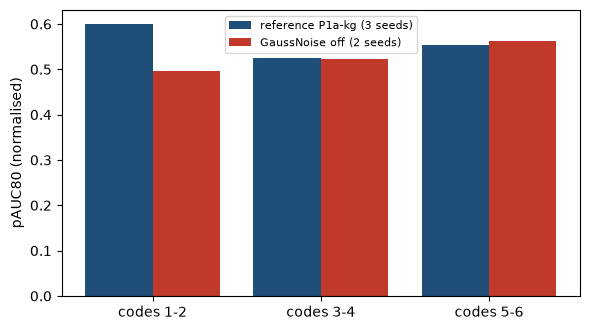

In [6]:
N_BOOT, BOOT_SEED = 1000, 0
d = bootstrap_mean_difference(t, [ev[r]["preds"] for r in cand_runs], [ev[r]["preds"] for r in ref_runs], N_BOOT, BOOT_SEED)
print("mean(candidate) - mean(reference), 95% CI:", {k: tuple(round(x, 4) for x in v) for k, v in ci95(d).items()})
print(f"gate: delta {delta['score']:+.6f} vs T(2) {T(2):.6f}")
groups = [c for c in p2.columns if c.startswith("pauc80 ")]
fig, ax = plt.subplots(figsize=(6, 3.4))
x = np.arange(len(groups))
ax.bar(x - 0.2, p2.loc["reference mean (n=3)", groups], 0.4, label="reference P1a-kg (3 seeds)", color="#1f4e79")
ax.bar(x + 0.2, p2.loc["candidate mean (n=2)", groups], 0.4, label="GaussNoise off (2 seeds)", color="#c0392b")
ax.set_xticks(x, [g.replace("pauc80 ", "") for g in groups])
ax.set_ylabel("pAUC80 (normalised)")
ax.legend(fontsize=8)
savefig("fig_phase2")

The candidate is level with the reference (Δ +0.0005, CI −0.016 to +0.015), far below the +0.024 the gate asks for.
Worse, pAUC80 and macro-AUC both **fell** in both seeds. The tiny gain comes only from FairGap, and FairGap shrank
because the code 1–2 group was pulled *down* (0.601 → 0.497), not because the weaker groups improved. A third seed
could not have changed the verdict: it would have needed a score above 0.6928. **We record this as a negative
result and keep the augmentation as it is.**

Two lessons. A visibly destructive augmentation can still help, presumably as regularisation, so seeing a defect
justifies an ablation, not an expected gain. And a score change should always be split into its components before
it is believed, especially when it is driven by FairGap on a small group.

## 5. Training time
On a Kaggle T4, each seed of the released recipe trained in 39.6, 40.3 and 40.5 minutes (5 folds × 10 epochs). The two
noise-off seeds took 38.2 and 35.2 minutes. The full set of reference predictions is produced in about 6 minutes of
inference.

## 6. Future work (Phase 3)
Under the gate, a two-seed candidate must beat the reference seed mean by about **+0.024**, more than any single
training change achieved here. The next experiments should therefore aim at large effects, not refinements. A
realistic expectation is 0.66–0.68; 0.7 would be a stretch.

1. **Representation.** The hard positives are the same for every seed (427/690), and are mostly melanomas ranked below
   BKL, NV and AKIEC, so more seeds of the same backbone will not fix them. Candidates:
   - an EfficientNet-B3 dermoscopy encoder;
   - a lower backbone learning rate (3e-4 → 1e-4) with the heads kept at 3e-3.
2. **A ranking loss for the pAUC tail.** pAUC80 is the weakest and heaviest component (0.5716 vs macro-AUC 0.8911). A
   pairwise softplus loss between benign logits and the lowest-scoring 20% of malignant logits targets that region directly.
3. **Groundwork:**
   - verify the direction of the skin-tone coding;
   - train clinical-only and tabular-only models, which have never been run;
   - bootstrap per-group pAUC80 to see how stable FairGap is on 111 lesions.
4. **Deprioritised:**
   - longer training: the curves plateau;
   - different crops: no framing problem was found;
   - self-supervised initialisation: we could not establish that suitable public weights were eligible.

## Takeaways
- Phase 1 produced a 0.6505 ensemble whose gain over the baseline comes mostly from averaging seeds.
- Phase 2's diagnosis points at representation and ranking. Its one controlled test, removing GaussNoise, was negative.
- Real progress needs changes worth about +0.024 per model.

Next, notebook 07 runs the released model on new lesions.